# Predicción del tiempo de llegada al siguiente punto de control — Experimentación

Corredor de transporte público de Cusco. Cuando un bus pasa por el punto de control k, se predice
cuántos minutos tardará en llegar al punto k+1 (tiempo de tramo, ETA). Contenido:

1. **Preprocesamiento de tiempos**: pasos por punto de control, limpieza, imputación y headways.
2. **GPS**: anomalías (Isolation Forest), lugares de detención (DBSCAN) y variables por tramo.
   **Altitud y clima**: Open-Meteo con las coordenadas exactas de cada punto de control.
3. **Dataset de modelado**: variables conocidas en el instante a(i,k) y objetivo a(i,k+Δ) − a(i,k).
4. **Experimentos**: E1 comparación de modelos (Δ=1), E2 horizonte, E3 ablación, E4 PCA,
   E5 hiperparámetros y costo, E6 análisis de errores + prueba de Wilcoxon.

Ejecutar desde la raíz del repositorio (lee `Dataset/*.csv`). Escribe tablas en `resultados/`,
figuras en `figuras/` y los mejores modelos en `modelos/` (para la demo).
Tiempo aproximado: ~20 min en una laptop. La primera ejecución descarga el clima de Open-Meteo (requiere
internet) y lo guarda en `datos_externos/`; las siguientes lo leen de ahí.

In [1]:
import json
import time
import warnings
from urllib.request import urlopen
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from sklearn.cluster import DBSCAN
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import AdaBoostRegressor, HistGradientBoostingRegressor, IsolationForest, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import ParameterSampler
from sklearn.neighbors import BallTree, KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

SEED = 42
DATA = Path("Dataset")
RES, FIG, MOD = Path("resultados"), Path("figuras"), Path("modelos")
for d in (RES, FIG, MOD):
    d.mkdir(exist_ok=True)

DELTAS = [1, 3, 5]          # horizontes: siguiente punto, 3 y 5 puntos más adelante
DELTA_MAIN = 1              # problema principal: llegada al siguiente punto de control
TRAIN_END, VAL_END = "2025-01-22", "2025-01-26"   # partición temporal por días
MAX_DELAY = 60              # |retraso| > 60 min se considera error de registro
MAX_H = 60                  # headways > 60 min = fin de servicio / error
MAX_AGE = 60                # un bus que terminó el tramo hace > 60 min ya no informa del tráfico actual
SLOW = 5                    # km/h: el GPS casi no registra velocidad 0, se usa "detenido o casi detenido"
N_ITER = 6                  # combinaciones de hiperparámetros por modelo
SVM_N = 8000                # submuestra para SVM (costo cuadrático)

## 1. Preprocesamiento de `Times.csv`

Cada fila es una vuelta con tres arreglos de 18 valores (hora programada, hora real y retraso).
Se convierte a una fila por **paso** (vuelta i, punto de control k). Reglas de limpieza:

- `end_time = 00:00:00` → el paso **no fue registrado** (es el origen del `-` en `difference_time`).
- |retraso| > 60 min → error de registro.
- Hora real menor que la de un punto anterior de la misma vuelta → error (no monotónico).
- Isolation Forest sobre el retraso y la desviación del tramo para marcar anomalías restantes.

In [2]:
t = pd.read_csv(DATA / "Times.csv", dtype={"vehicle_id_id": str})
arr = ["start_time", "end_time", "difference_time"]
for c in arr:
    t[c] = t[c].str.strip("{}").str.split(",")
p = t.explode(arr).reset_index(drop=True)
p["k"] = p.groupby("id").cumcount() + 1
p = p.rename(columns={"id": "trip", "vehicle_id_id": "veh"})
p["s"] = pd.to_timedelta(p.start_time).dt.total_seconds() / 60   # minutos desde medianoche
p["a"] = pd.to_timedelta(p.end_time).dt.total_seconds() / 60
p = p[["trip", "date", "veh", "lap", "k", "s", "a"]].sort_values(["trip", "k"]).reset_index(drop=True)

limpieza = {"pasos totales": len(p)}
p.loc[p.a == 0, "a"] = np.nan
limpieza["no registrados (00:00:00)"] = int(p.a.isna().sum())
p["delay"] = p.a - p.s
bad = p.delay.abs() > MAX_DELAY
limpieza[f"|retraso| > {MAX_DELAY} min"] = int(bad.sum())
p.loc[bad, ["a", "delay"]] = np.nan
prev_max = p.groupby("trip").a.cummax().groupby(p.trip).shift().groupby(p.trip).ffill()
bad = p.a < prev_max
limpieza["no monotónicos"] = int(bad.sum())
p.loc[bad, ["a", "delay"]] = np.nan

# desviación del tramo k-1 -> k respecto a lo programado (= cambio de retraso)
p["ddelay"] = p.delay - p.groupby("trip").delay.shift()
ok = p[["delay", "ddelay"]].notna().all(axis=1)
iso_p = IsolationForest(contamination=0.001, random_state=SEED).fit(p.loc[ok, ["delay", "ddelay"]])
bad = pd.Series(False, index=p.index)
bad[ok] = iso_p.predict(p.loc[ok, ["delay", "ddelay"]]) == -1
limpieza["anomalías Isolation Forest"] = int(bad.sum())
p.loc[bad, ["a", "delay"]] = np.nan
limpieza["pasos válidos"] = int(p.a.notna().sum())
pd.Series(limpieza, name="pasos").to_frame()

,pasos
pasos totales,84726
no registrados (00:00:00),7746
|retraso| > 60 min,156
no monotónicos,0
anomalías Isolation Forest,71
pasos válidos,76753


**Imputación y headway.** El headway con el bus de adelante es una variable útil (un bus con más
tiempo detrás del anterior encuentra más pasajeros y demora más). Si al bus de adelante le falta un
paso, el headway saldría inflado; por eso el retraso faltante se interpola dentro de la vuelta
(máximo 2 puntos seguidos). Los pasos imputados solo se usan para calcular headways, nunca como objetivo.

In [3]:
p["delay_i"] = p.groupby("trip").delay.transform(lambda d: d.interpolate(limit=2, limit_area="inside"))
p["a_i"] = p.s + p.delay_i
p["imp"] = p.a.isna() & p.a_i.notna()
print(f"pasos imputados: {p.imp.sum()}  | sin dato tras imputar: {p.a_i.isna().sum()}")

q = p[p.a_i.notna()].sort_values(["date", "k", "a_i"])
g = q.groupby(["date", "k"])
q["h"] = q.a_i - g.a_i.shift()
q["hp"] = q.s - g.s.shift()
q.loc[~(q.h.between(0, MAX_H) & q.hp.between(0, MAX_H, inclusive="right")), "h"] = np.nan
p = p.merge(q[["trip", "k", "h"]], on=["trip", "k"], how="left")
print(f"headways válidos: {p.h.notna().sum()}")

pasos imputados: 1398  | sin dato tras imputar: 6575
headways válidos: 76484


### Análisis exploratorio del tiempo de tramo
Tiempo real T = a(i,k+1) − a(i,k) frente al programado s(i,k+1) − s(i,k), solo con pasos reales.

tramos válidos: 70777 | tiempo medio 9.67 min | error del horario (MAE) 1.56 min | σ de la desviación 2.16 min
vuelta completa: programada 161 min, real 164 min (mediana); P10–P90 real 148–179 min
desviación media por hora (min): {4: -1.05, 5: -1.24, 6: -0.42, 7: 0.0, 8: 0.09, 9: 0.17, 10: 0.32, 11: 0.38, 12: 0.3, 13: 0.16, 14: 0.18, 15: 0.26, 16: 0.36, 17: 0.54, 18: 0.88, 19: 0.88, 20: 0.52, 21: 0.03, 22: -0.42}


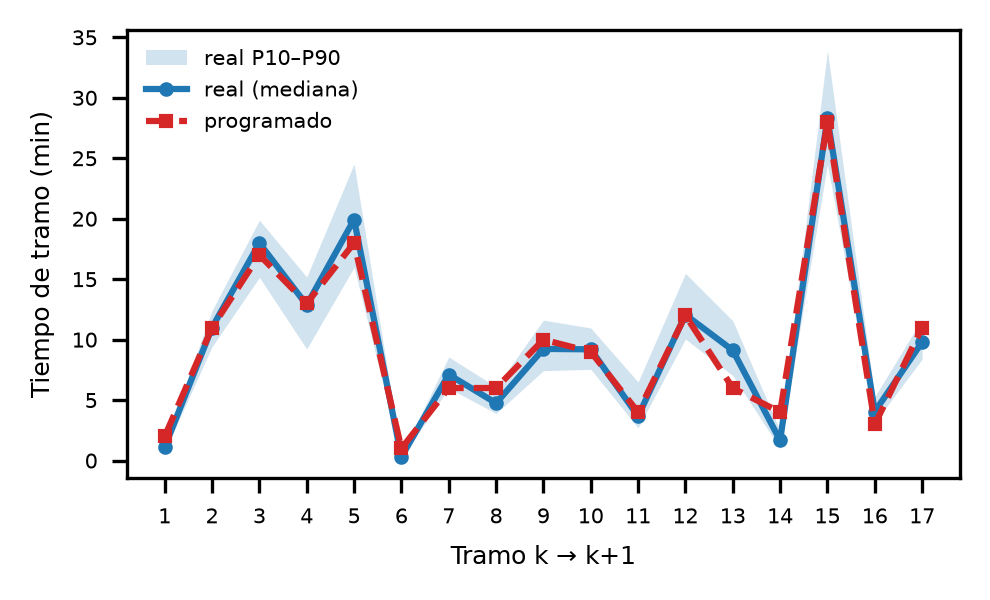

k,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
prog,2.00,11.00,17.00,13.00,18.00,1.00,6.00,6.00,10.00,9.00,4.00,12.00,6.00,4.00,28.00,3.00,11.00
real,1.12,11.00,17.98,12.87,19.93,0.30,7.12,4.75,9.23,9.20,3.67,12.06,9.12,1.67,28.32,4.05,9.80
p10,0.77,9.42,15.14,9.23,15.98,0.22,5.98,3.90,7.43,7.55,2.72,10.05,7.03,0.98,24.52,3.17,8.38
p90,1.53,12.41,19.88,15.18,24.53,0.43,8.57,6.10,11.62,10.97,6.50,15.49,11.57,2.47,33.90,5.28,11.71
mae_horario,0.87,0.94,1.59,1.46,2.39,0.69,1.26,1.34,1.47,1.11,1.35,1.73,3.16,2.12,2.41,1.21,1.44


In [4]:
p = p.sort_values(["trip", "k"]).reset_index(drop=True)
gt = p.groupby("trip")
seg_t = p.assign(T=gt.a.shift(-1) - p.a, Tp=gt.s.shift(-1) - p.s).dropna(subset=["T"])
seg_t = seg_t[seg_t.k < 18]
seg_t["dev"] = seg_t["T"] - seg_t.Tp
vuelta = p[p.k.isin([1, 18])].pivot_table(index="trip", columns="k", values=["a", "s"])
vr = (vuelta[("a", 18)] - vuelta[("a", 1)]).dropna()
vp = (vuelta[("s", 18)] - vuelta[("s", 1)]).loc[vr.index]
print(f"tramos válidos: {len(seg_t)} | tiempo medio {seg_t['T'].mean():.2f} min | "
      f"error del horario (MAE) {seg_t.dev.abs().mean():.2f} min | σ de la desviación {seg_t.dev.std():.2f} min")
print(f"vuelta completa: programada {vp.median():.0f} min, real {vr.median():.0f} min (mediana); "
      f"P10–P90 real {vr.quantile(.1):.0f}–{vr.quantile(.9):.0f} min")
by_h = seg_t.assign(hora=(seg_t.s // 60).astype(int)).groupby("hora").dev.mean()
print("desviación media por hora (min):", by_h.round(2).to_dict())

by_k = seg_t.groupby("k").agg(prog=("Tp", "median"), real=("T", "median"),
                              p10=("T", lambda x: x.quantile(.1)), p90=("T", lambda x: x.quantile(.9)),
                              mae_horario=("dev", lambda x: x.abs().mean()))
fig, ax = plt.subplots(figsize=(3.4, 2.1), dpi=300)
ax.fill_between(by_k.index, by_k.p10, by_k.p90, color="tab:blue", alpha=0.2, lw=0, label="real P10–P90")
ax.plot(by_k.index, by_k.real, "o-", ms=2.5, color="tab:blue", label="real (mediana)")
ax.plot(by_k.index, by_k.prog, "s--", ms=2.5, color="tab:red", label="programado")
ax.set_xlabel("Tramo k → k+1", fontsize=6); ax.set_ylabel("Tiempo de tramo (min)", fontsize=6)
ax.set_xticks(range(1, 18)); ax.tick_params(labelsize=5); ax.legend(fontsize=5, frameon=False)
fig.tight_layout(); fig.savefig(FIG / "fig2_tramos.png"); plt.show()
by_k.round(2).T

## 2. Preprocesamiento de `Monitoring.csv` (GPS)

- Se eliminan registros duplicados (mismo vehículo, fecha y hora).
- **Isolation Forest** sobre (latitud, longitud, velocidad) elimina saltos de GPS y velocidades imposibles.
- **DBSCAN** (distancia haversine, eps = 25 m) sobre los registros detenidos (≤ 5 km/h; el equipo GPS casi
  no registra velocidad 0, solo 0,6 % de los registros) identifica los lugares donde los buses se
  detienen de forma recurrente (paraderos reales, terminal, semáforos).

In [5]:
m = pd.read_csv(DATA / "Monitoring.csv", dtype={"vehicle_id_id": str},
                usecols=["date", "time", "latitude", "longitude", "speed", "vehicle_id_id"])
m = m.rename(columns={"vehicle_id_id": "veh"})
n0 = len(m)
m = m.drop_duplicates(["veh", "date", "time"])
m["t"] = pd.to_timedelta(m.time).dt.total_seconds() / 60
iso_g = IsolationForest(contamination=0.005, random_state=SEED, n_jobs=-1)
out = iso_g.fit_predict(m[["latitude", "longitude", "speed"]]) == -1
print(f"GPS: {n0} registros, {n0 - len(m)} duplicados, {out.sum()} anomalías (Isolation Forest)")
m = m[~out].reset_index(drop=True)

GPS: 1630431 registros, 6783 duplicados, 8104 anomalías (Isolation Forest)


DBSCAN: 104 lugares de detención recurrentes; 92.9% de los registros detenidos cae en uno


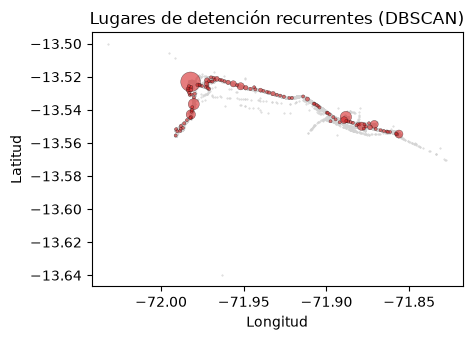

In [6]:
EPS = 25 / 6_371_000   # 25 m en radianes
stop = m[m.speed <= SLOW]
samp = stop.sample(min(40_000, len(stop)), random_state=SEED)
Xs = np.radians(samp[["latitude", "longitude"]].to_numpy())
db = DBSCAN(eps=EPS, min_samples=40, metric="haversine", algorithm="ball_tree").fit(Xs)
core, core_lab = Xs[db.core_sample_indices_], db.labels_[db.core_sample_indices_]
# asignar todos los registros detenidos al cluster del punto núcleo más cercano (si está a < eps)
dist, idx = BallTree(core, metric="haversine").query(np.radians(stop[["latitude", "longitude"]].to_numpy()), k=1)
m["par"] = -1
m.loc[stop.index, "par"] = np.where(dist[:, 0] <= EPS, core_lab[idx[:, 0]], -1)
print(f"DBSCAN: {len(set(core_lab))} lugares de detención recurrentes; "
      f"{(m.loc[stop.index, 'par'] >= 0).mean():.1%} de los registros detenidos cae en uno")
centros = m[m.par >= 0].groupby("par")[["latitude", "longitude"]].median()
centros["registros"] = m[m.par >= 0].groupby("par").size()
centros.to_csv(RES / "paraderos_dbscan.csv")

fig, ax = plt.subplots(figsize=(7, 3.5))
bg = m.sample(60_000, random_state=SEED)
ax.scatter(bg.longitude, bg.latitude, s=0.2, c="lightgray", rasterized=True)
ax.scatter(centros.longitude, centros.latitude, s=np.clip(centros.registros / 50, 5, 200),
           c="tab:red", alpha=0.6, edgecolor="k", linewidth=0.3)
ax.set(xlabel="Longitud", ylabel="Latitud", title="Lugares de detención recurrentes (DBSCAN)")
ax.set_aspect("equal")
fig.tight_layout(); fig.savefig(FIG / "exp_dbscan_paraderos.png", dpi=200); plt.show()

**Variables GPS por tramo.** Cada registro GPS se asigna al tramo que termina en el siguiente paso
del mismo vehículo (k−1 → k), con `merge_asof`. Por tramo se calcula: velocidad media, fracción de
registros detenidos, fracción detenida en lugares DBSCAN y número de lugares DBSCAN distintos.

In [7]:
passes = p.loc[p.a_i.notna(), ["veh", "date", "a_i", "trip", "k"]].sort_values("a_i")
mg = pd.merge_asof(m.sort_values("t"), passes, left_on="t", right_on="a_i", by=["veh", "date"],
                   direction="forward", tolerance=60).dropna(subset=["trip"])
mg["stop"] = mg.speed <= SLOW
mg["stop_par"] = mg.stop & (mg.par >= 0)
seg = mg.groupby(["trip", "k"]).agg(v=("speed", "mean"), stop=("stop", "mean"),
                                    stop_par=("stop_par", "mean"),
                                    npar=("par", lambda s: s[s >= 0].nunique())).reset_index()
seg["trip"] = seg.trip.astype(p.trip.dtype)
seg["k"] = seg.k.astype(int)
print(f"tramos con GPS: {len(seg)} de {p.a_i.notna().sum()}")
seg.describe().round(2)

tramos con GPS: 76928 de 78151


,trip,k,v,stop,stop_par,npar
count,76928.00,76928.00,76928.00,76928.00,76928.00,76928.00
mean,22430.05,9.43,23.86,0.03,0.03,0.41
std,9155.28,5.20,5.67,0.07,0.07,0.66
min,6653.00,1.00,0.00,0.00,0.00,0.00
25%,14284.00,5.00,19.83,0.00,0.00,0.00
50%,22359.00,9.00,23.76,0.00,0.00,0.00
75%,30186.25,14.00,27.59,0.04,0.04,1.00
max,38832.00,18.00,58.00,1.00,1.00,7.00


### Altitud y clima (Open-Meteo)

Se consulta Open-Meteo con las coordenadas **exactas** de los 18 puntos de control (mediana del GPS en
el instante de paso), no con un punto genérico de la ciudad:

- **Altitud**: API de elevación de Open-Meteo (modelo digital de elevación de 90 m) en cada punto.
- **Clima**: API histórica (reanálisis ERA5), hora local de Lima. Se envía la altitud de cada punto para
  que la temperatura se corrija por altura, y `cell_selection=nearest` para usar la celda de la grilla
  más cercana a cada punto. La grilla del modelo tiene ~7 km, así que puntos cercanos comparten celda;
  la tabla de verificación muestra a qué distancia quedó la celda de cada punto.

Variables: temperatura, humedad relativa, precipitación de la hora y de las últimas 3 horas, nubosidad y
viento. A cada paso se le asigna el clima de su punto de control en la hora en que ocurrió.

In [8]:
CLIMA = Path("datos_externos/clima_open_meteo.csv")
PUNTOS = Path("datos_externos/puntos_control_clima.csv")
VARS = ["temperature_2m", "relative_humidity_2m", "precipitation", "cloud_cover", "wind_speed_10m"]
pc = p.loc[p.a.notna(), ["date", "veh", "k", "a"]].sort_values("a")
cp = pd.merge_asof(pc, m[["date", "veh", "t", "latitude", "longitude"]].sort_values("t"), left_on="a", right_on="t",
                   by=["date", "veh"], tolerance=1.0, direction="nearest").groupby("k")[["latitude", "longitude"]].median()
if not (CLIMA.exists() and PUNTOS.exists()):
    lat, lon = ",".join(cp.latitude.round(5).astype(str)), ",".join(cp.longitude.round(5).astype(str))
    cp["alt"] = json.load(urlopen(f"https://api.open-meteo.com/v1/elevation?latitude={lat}&longitude={lon}", timeout=60))["elevation"]
    url = (f"https://archive-api.open-meteo.com/v1/archive?latitude={lat}&longitude={lon}"
           f"&elevation={','.join(cp.alt.astype(str))}&cell_selection=nearest"
           f"&start_date={m.date.min()}&end_date={m.date.max()}&hourly={','.join(VARS)}&timezone=America%2FLima")
    locs = json.load(urlopen(url, timeout=120))
    cp["lat_celda"] = [loc["latitude"] for loc in locs]
    cp["lon_celda"] = [loc["longitude"] for loc in locs]
    cp["alt_usada"] = [loc["elevation"] for loc in locs]
    PUNTOS.parent.mkdir(exist_ok=True)
    cp.to_csv(PUNTOS)
    pd.concat([pd.DataFrame(loc["hourly"]).assign(k=k_) for k_, loc in zip(cp.index, locs)]).to_csv(CLIMA, index=False)
cp = pd.read_csv(PUNTOS, index_col="k")
cp.to_csv(RES / "puntos_control.csv")

# verificación: cada punto usa sus propias coordenadas y altitud
rad = np.radians
cp["dist_celda_km"] = 2 * 6371 * np.arcsin(np.sqrt(
    np.sin(rad(cp.lat_celda - cp.latitude) / 2) ** 2
    + np.cos(rad(cp.latitude)) * np.cos(rad(cp.lat_celda)) * np.sin(rad(cp.lon_celda - cp.longitude) / 2) ** 2))
assert (cp.alt_usada == cp.alt).all(), "Open-Meteo no usó la altitud enviada"
print(f"{len(cp)} puntos consultados | {len(cp[['lat_celda', 'lon_celda']].drop_duplicates())} celdas de la grilla | "
      f"distancia punto → celda: media {cp.dist_celda_km.mean():.1f} km, máx. {cp.dist_celda_km.max():.1f} km | "
      f"altitud {cp.alt.min():.0f}–{cp.alt.max():.0f} m")
cp.round(4)

18 puntos consultados | 2 celdas de la grilla | distancia punto → celda: media 3.0 km, máx. 5.0 km | altitud 3185–3519 m


,latitude,longitude,alt,lat_celda,lon_celda,alt_usada,dist_celda_km
k,,,,,,,
1,-13.5552,-71.8568,3188.0,-13.5325,-71.8681,3188.0,2.8031
2,-13.5535,-71.8607,3185.0,-13.5325,-71.8681,3185.0,2.4669
3,-13.5446,-71.8883,3242.0,-13.5325,-71.8681,3242.0,2.5591
4,-13.5288,-71.9372,3313.0,-13.5325,-71.9505,3313.0,1.5041
5,-13.5216,-71.9651,3367.0,-13.5325,-71.9505,3367.0,1.9880
6,-13.5256,-71.9833,3412.0,-13.5325,-71.9505,3412.0,3.6273
7,-13.5259,-71.9827,3417.0,-13.5325,-71.9505,3417.0,3.5510
8,-13.5359,-71.9804,3370.0,-13.5325,-71.9505,3370.0,3.2478
9,-13.5442,-71.9821,3377.0,-13.5325,-71.9505,3377.0,3.6531


In [9]:
cl = pd.read_csv(CLIMA).sort_values(["k", "time"])
cl["date"], cl["hora_c"] = cl.time.str[:10], cl.time.str[11:13].astype(int)
cl["precip_3h"] = cl.groupby("k").precipitation.transform(lambda x: x.rolling(3, min_periods=1).sum())
cl = cl.rename(columns={"temperature_2m": "temp", "relative_humidity_2m": "hum", "precipitation": "precip",
                        "cloud_cover": "nubes", "wind_speed_10m": "viento"})
cl = cl[["k", "date", "hora_c", "temp", "hum", "precip", "precip_3h", "nubes", "viento"]]
print(f"clima: {len(cl)} registros horarios; {cl.groupby('k').precip.sum().nunique()} series de precipitación distintas "
      f"(celdas de la grilla; la temperatura se corrige por altitud en cada punto); "
      f"horas con lluvia (≥ 0,1 mm): {(cl.precip >= 0.1).mean():.1%}")

# efecto de la lluvia sobre el tiempo de tramo (análisis exploratorio)
st = seg_t.assign(hora_c=(seg_t.a // 60).astype(int)).merge(cl, on=["k", "date", "hora_c"], how="left")
st["lluvia"] = pd.cut(st.precip, [-0.01, 0.0999, 1, 100], labels=["seco", "lluvia débil (0,1–1 mm)", "lluvia (> 1 mm)"])
st.groupby("lluvia", observed=True).agg(tramos=("dev", "size"), desviacion_media=("dev", "mean"),
                                         mae_horario=("dev", lambda x: x.abs().mean())).round(3)

clima: 13824 registros horarios; 2 series de precipitación distintas (celdas de la grilla; la temperatura se corrige por altitud en cada punto); horas con lluvia (≥ 0,1 mm): 46.7%


,tramos,desviacion_media,mae_horario
lluvia,,,
seco,33005,0.238,1.595
"lluvia débil (0,1–1 mm)",31947,0.216,1.506
lluvia (> 1 mm),5825,0.351,1.691


## 3. Dataset de modelado

Para cada paso **real** del bus i por el punto k se predice y = a(i,k+Δ) − a(i,k) con variables
conocidas en el instante a(i,k):

| Grupo | Variables |
|---|---|
| Bus i | retraso δ(i,k), cambio de retraso en el último tramo, tiempo real del último tramo, headway con el bus de adelante, vuelta |
| Buses recientes | tiempo del último bus que **terminó** el mismo tramo antes de a(i,k), media de los 3 últimos y hace cuánto lo terminó |
| GPS | velocidad media y fracción detenida del bus i en su último tramo y del último bus en el tramo a predecir |
| DBSCAN | fracción detenida en paraderos y n.º de paraderos del bus i (último tramo) y del último bus (tramo a predecir) |
| Clima | temperatura, humedad, precipitación (hora y 3 h), nubosidad y viento en el punto k a la hora del paso |
| Altitud | altitud del punto k y desnivel hasta el punto k+Δ (m) |
| Contexto | k, hora, día de la semana, tiempo programado del tramo, vehículo |

In [10]:
key = ["trip", "k"]
p = p.merge(seg, on=key, how="left").sort_values(key).reset_index(drop=True)
gt = p.groupby("trip")
p["T_prev"] = p.a - gt.a.shift()
p["ddelay_k"] = p.delay_i - gt.delay_i.shift()
p = p.rename(columns={"delay": "delay_k", "h": "h_k", "v": "v_i", "stop": "stop_i",
                      "stop_par": "stoppar_i", "npar": "npar_i"})
segj = seg.rename(columns={"trip": "trip_c", "k": "kc", "v": "v_last", "stop": "stop_last", "npar": "npar_last"})
segj["trip_c"] = segj.trip_c.astype(float)   # merge_asof deja trip_c como float (hay NaN)

rows = []
for D in DELTAS:
    b = p[p.a.notna() & (p.k + D <= 18)].copy()
    b["delta"], b["kt"] = D, b.k + D
    nxt = p[["trip", "k", "a", "s"]].rename(columns={"k": "kt", "a": "a_t", "s": "s_t"})
    b = b.merge(nxt, on=["trip", "kt"], how="inner").dropna(subset=["a_t"])
    b["y"], b["sp"] = b.a_t - b.a, b.s_t - b.s
    # buses que ya terminaron el mismo tramo k -> k+Δ: el más reciente antes de a(i,k)
    comp = b[["date", "k", "a_t", "y", "trip"]].rename(columns={"a_t": "c", "y": "T_last", "trip": "trip_c"})
    comp = comp.sort_values("c")
    comp["T_roll3"] = comp.groupby(["date", "k"]).T_last.transform(lambda x: x.rolling(3, min_periods=1).mean())
    b = pd.merge_asof(b.sort_values("a"), comp, left_on="a", right_on="c", by=["date", "k"],
                      direction="backward", allow_exact_matches=False)
    b["age_last"] = b.a - b.c
    stale = b.age_last > MAX_AGE
    b.loc[stale, ["T_last", "T_roll3", "age_last", "trip_c"]] = np.nan
    b["kc"] = b.k + 1   # GPS del último bus en el primer tramo de su recorrido k -> k+1
    b = b.merge(segj[["trip_c", "kc", "v_last", "stop_last", "npar_last"]], on=["trip_c", "kc"], how="left")
    rows.append(b)
D_all = pd.concat(rows, ignore_index=True)
D_all["hour"] = D_all.s / 60
D_all["dow"] = pd.to_datetime(D_all.date).dt.dayofweek
D_all["hora_c"] = (D_all.a // 60).astype(int)
D_all = D_all.merge(cl, on=["k", "date", "hora_c"], how="left")
D_all["alt"] = D_all.k.map(cp.alt)
D_all["desnivel"] = D_all.kt.map(cp.alt) - D_all.alt
D_all["split"] = np.where(D_all.date <= TRAIN_END, "train", np.where(D_all.date <= VAL_END, "val", "test"))

G_I = ["delay_k", "ddelay_k", "T_prev", "h_k", "lap"]
G_REC = ["T_last", "T_roll3", "age_last"]
G_GPS = ["v_i", "stop_i", "v_last", "stop_last"]
G_DB = ["stoppar_i", "npar_i", "npar_last"]
G_CLIMA = ["temp", "hum", "precip", "precip_3h", "nubes", "viento"]
G_ALT = ["alt", "desnivel"]
G_CTX = ["k", "hour", "dow", "sp"]
CAT = ["veh"]
NUM = G_I + G_REC + G_GPS + G_DB + G_CLIMA + G_ALT + G_CTX
D_all[list(dict.fromkeys(["date", "split", "delta", "trip", "veh", "s", "a"] + NUM + ["y"]))].to_pickle(RES / "dataset_modelo.pkl")

print(D_all.groupby(["delta", "split"]).size().unstack())
D_all[NUM + ["y"]].describe().T.round(2)

split   test  train    val
delta                     
1      16889  43823  10065
3      14931  38831   8921
5      12792  33317   7642


,count,mean,std,min,25%,50%,75%,max
delay_k,187211.0,0.45,4.46,-54.15,-1.35,0.07,1.90,49.50
ddelay_k,173621.0,0.22,2.05,-8.37,-0.97,-0.20,1.20,56.35
T_prev,172394.0,9.11,6.54,0.08,3.93,8.68,12.45,62.35
h_k,184476.0,5.71,2.73,0.00,4.02,5.35,6.98,38.42
lap,187211.0,2.77,1.38,1.00,2.00,3.00,4.00,8.00
T_last,182362.0,26.77,17.87,0.08,10.62,25.43,40.22,98.87
T_roll3,182362.0,26.80,17.83,0.17,10.63,25.40,40.41,78.43
age_last,182362.0,3.82,3.31,0.02,1.55,3.15,5.20,59.77
v_i,183869.0,23.52,5.68,0.00,19.45,23.17,27.20,56.50
stop_i,183869.0,0.03,0.07,0.00,0.00,0.00,0.05,1.00


## 4. Modelos, referencias y protocolo

- **Referencias**:
  - *horario*: ŷ = tiempo programado del tramo.
  - *histórico*: ŷ = tiempo medio del tramo a esa hora en entrenamiento (k × hora).
  - *último bus*: ŷ = tiempo del último bus que terminó el mismo tramo (si no hay, el horario).
- **Modelos** (scikit-learn): Ridge, KNN, árbol de decisión, SVM-RBF (submuestra), Random Forest,
  AdaBoost, Gradient Boosting (HistGradientBoosting) y MLP.
- **Preprocesamiento**: imputación por mediana + estandarización (numéricas) y one-hot (vehículo).
- **Ajuste**: `N_ITER` combinaciones de la Tabla II evaluadas en validación (MAE); el mejor se
  reentrena con entrenamiento + validación y se evalúa **una vez** en prueba.

In [11]:
def prep(num, pca=False):
    steps_num = [("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]
    ct = ColumnTransformer([("num", Pipeline(steps_num), num),
                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    return [("prep", ct)] + ([("pca", PCA(n_components=0.95, random_state=SEED))] if pca else [])


REG = {
    "Ridge": (Ridge(), {"alpha": [0.01, 0.1, 1, 10, 100]}),
    "KNN": (KNeighborsRegressor(n_jobs=-1), {"n_neighbors": [5, 15, 51], "weights": ["uniform", "distance"]}),
    "Árbol": (DecisionTreeRegressor(random_state=SEED), {"max_depth": [5, 10, 20], "min_samples_leaf": [1, 20, 100]}),
    "SVM": (SVR(), {"C": [0.1, 1, 10], "gamma": [0.01, 0.1, "scale"]}),
    "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=-1),
                     {"n_estimators": [200, 500], "max_depth": [10, 20, None], "min_samples_leaf": [1, 5, 20]}),
    "AdaBoost": (AdaBoostRegressor(DecisionTreeRegressor(max_depth=4), random_state=SEED),
                 {"n_estimators": [100, 300], "learning_rate": [0.1, 1.0]}),
    "GradBoost": (HistGradientBoostingRegressor(random_state=SEED, max_iter=1000, early_stopping=True),
                  {"learning_rate": [0.03, 0.1], "max_depth": [4, 6, 8]}),
    "MLP": (MLPRegressor(random_state=SEED, early_stopping=True, max_iter=300),
            {"hidden_layer_sizes": [(64, 32), (128, 64, 32)], "alpha": [1e-4, 1e-3], "learning_rate_init": [1e-3, 1e-4]}),
}


def metrics(y, yhat):
    y, yhat = np.asarray(y), np.asarray(yhat)
    return {"MAE": mean_absolute_error(y, yhat), "RMSE": root_mean_squared_error(y, yhat),
            "MAPE_%": 100 * np.mean(np.abs(y - yhat) / np.maximum(y, 0.5)), "R2": r2_score(y, yhat)}


def baselines(d_fit, d):
    """Referencias sin aprendizaje; el histórico se calcula solo con d_fit (sin mirar prueba)."""
    hist_kh = d_fit.groupby(["k", d_fit.hour.astype(int)]).y.mean()
    hist_k = d_fit.groupby("k").y.mean()
    idx = pd.MultiIndex.from_arrays([d.k, d.hour.astype(int)])
    hist = pd.Series(hist_kh.reindex(idx).to_numpy(), index=d.index).fillna(d.k.map(hist_k))
    return {"Ref. horario": d.sp.to_numpy(), "Ref. histórico": hist.to_numpy(),
            "Ref. último bus": d.T_last.fillna(d.sp).to_numpy()}


def fit(name, est, params, d, num, pca=False):
    """Entrena el pipeline con los parámetros dados; SVM usa una submuestra."""
    pipe = Pipeline(prep(num, pca) + [("model", est)]).set_params(**{f"model__{k}": v for k, v in params.items()})
    if name == "SVM" and len(d) > SVM_N:
        d = d.sample(SVM_N, random_state=SEED)
    t0 = time.perf_counter()
    pipe.fit(d[num + CAT], d.y)
    return pipe, time.perf_counter() - t0


def tune(name, d_tr, d_va, num):
    est, grid = REG[name]
    n = int(np.prod([len(v) for v in grid.values()]))
    cands = list(ParameterSampler(grid, n_iter=min(N_ITER, n), random_state=SEED))
    recs = []
    for prm in cands:
        pipe, tfit = fit(name, est, prm, d_tr, num)
        recs.append({"modelo": name, "params": str(prm), **metrics(d_va.y, pipe.predict(d_va[num + CAT])), "t_fit_s": tfit})
    recs = pd.DataFrame(recs)
    return cands[int(recs.MAE.idxmin())], recs


def evaluate(name, prm, d_trva, d_te, num, pca=False):
    pipe, tfit = fit(name, REG[name][0], prm, d_trva, num, pca)
    t0 = time.perf_counter()
    yhat = pipe.predict(d_te[num + CAT])
    return pipe, yhat, {**metrics(d_te.y, yhat), "t_fit_s": tfit, "t_pred_s": time.perf_counter() - t0}


def split(D):
    d = D_all[D_all.delta == D]
    return d[d.split == "train"], d[d.split == "val"], d[d.split != "test"], d[d.split == "test"]

## E1. Comparación de modelos (Δ = 1: llegada al siguiente punto de control)

In [12]:
d_tr, d_va, d_trva, d_te = split(DELTA_MAIN)
PRED = baselines(d_trva, d_te)
tab = [{"modelo": k, **metrics(d_te.y, v)} for k, v in PRED.items()]
BEST_PRM, SEARCH = {}, []
for name in REG:
    t0 = time.perf_counter()
    prm, recs = tune(name, d_tr, d_va, NUM)
    SEARCH.append(recs)
    BEST_PRM[name] = prm
    pipe, yhat, sc = evaluate(name, prm, d_trva, d_te, NUM)
    PRED[name] = yhat
    tab.append({"modelo": name, **sc, "mejores_hiperparámetros": str(prm)})
    if name in ("GradBoost", "RandomForest"):
        joblib.dump(pipe, MOD / f"eta_{name}_delta{DELTA_MAIN}.joblib")
    print(f"{name:12s} listo en {time.perf_counter() - t0:5.1f} s -> MAE {sc['MAE']:.3f}")
E1 = pd.DataFrame(tab)
E1.to_csv(RES / f"E1_eta_delta{DELTA_MAIN}.csv", index=False)
pd.concat(SEARCH).to_csv(RES / "E5_busqueda_hiperparametros.csv", index=False)
E1.round(3)

Ridge        listo en   1.5 s -> MAE 1.040


KNN          listo en   7.4 s -> MAE 1.053


Árbol        listo en   5.2 s -> MAE 0.911


SVM          listo en  89.6 s -> MAE 1.065


RandomForest listo en 150.2 s -> MAE 0.849


AdaBoost     listo en 292.3 s -> MAE 1.112


GradBoost    listo en  19.7 s -> MAE 0.854


MLP          listo en 127.9 s -> MAE 0.947


,modelo,MAE,RMSE,MAPE_%,R2,t_fit_s,t_pred_s,mejores_hiperparámetros
0,Ref. horario,1.531,2.089,36.499,0.920,NaN,NaN,NaN
1,Ref. histórico,0.953,1.481,13.198,0.960,NaN,NaN,NaN
2,Ref. último bus,1.191,1.741,16.823,0.944,NaN,NaN,NaN
3,Ridge,1.040,1.510,20.134,0.958,0.333,0.029,{'alpha': 0.01}
4,KNN,1.053,1.575,16.717,0.955,0.210,1.563,"{'weights': 'distance', 'n_neighbors': 15}"
5,Árbol,0.911,1.373,13.108,0.965,0.989,0.025,"{'min_samples_leaf': 100, 'max_depth': 20}"
6,SVM,1.065,1.576,21.262,0.954,7.945,10.385,"{'gamma': 'scale', 'C': 10}"
7,RandomForest,0.849,1.278,11.974,0.970,16.564,0.170,"{'n_estimators': 200, 'min_samples_leaf': 5, '..."
8,AdaBoost,1.112,1.523,22.787,0.957,26.081,0.272,"{'n_estimators': 100, 'learning_rate': 0.1}"
9,GradBoost,0.854,1.257,12.959,0.971,3.964,0.138,"{'max_depth': 6, 'learning_rate': 0.03}"


mejor modelo: RandomForest | mejor referencia: Ref. histórico


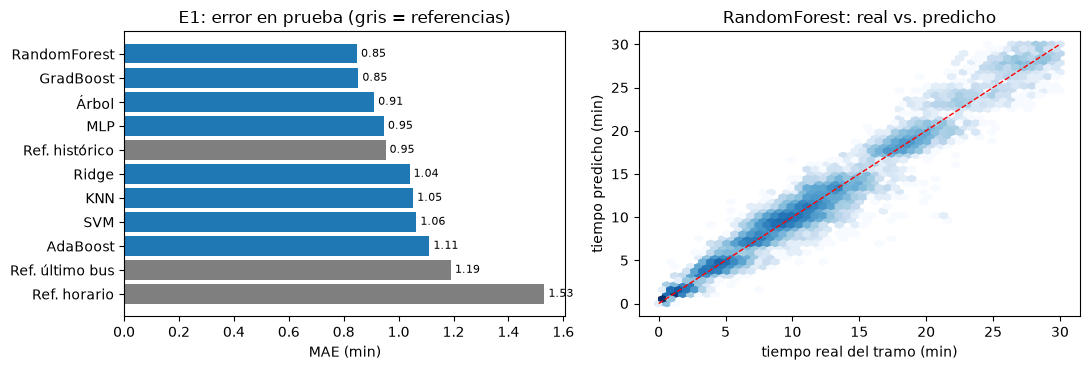

In [13]:
e = E1.sort_values("MAE")
best = e[~e.modelo.str.startswith("Ref.")].modelo.iloc[0]
best_ref = e[e.modelo.str.startswith("Ref.")].modelo.iloc[0]
print("mejor modelo:", best, "| mejor referencia:", best_ref)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh(e.modelo, e.MAE, color=["tab:gray" if m_.startswith("Ref.") else "tab:blue" for m_ in e.modelo])
axes[0].invert_yaxis()
for i, v in enumerate(e.MAE):
    axes[0].text(v, i, f" {v:.2f}", va="center", fontsize=8)
axes[0].set(xlabel="MAE (min)", title="E1: error en prueba (gris = referencias)")
axes[1].hexbin(d_te.y, PRED[best], gridsize=50, bins="log", cmap="Blues", extent=(0, 30, 0, 30))
axes[1].plot([0, 30], [0, 30], "r--", lw=1)
axes[1].set(xlabel="tiempo real del tramo (min)", ylabel="tiempo predicho (min)", title=f"{best}: real vs. predicho")
fig.tight_layout(); fig.savefig(FIG / "exp1_comparacion.png", dpi=200); plt.show()

## E2. Efecto del horizonte: ETA a 1, 3 y 5 puntos de control
Se reutilizan los mejores hiperparámetros de Δ = 1 para todos los modelos.

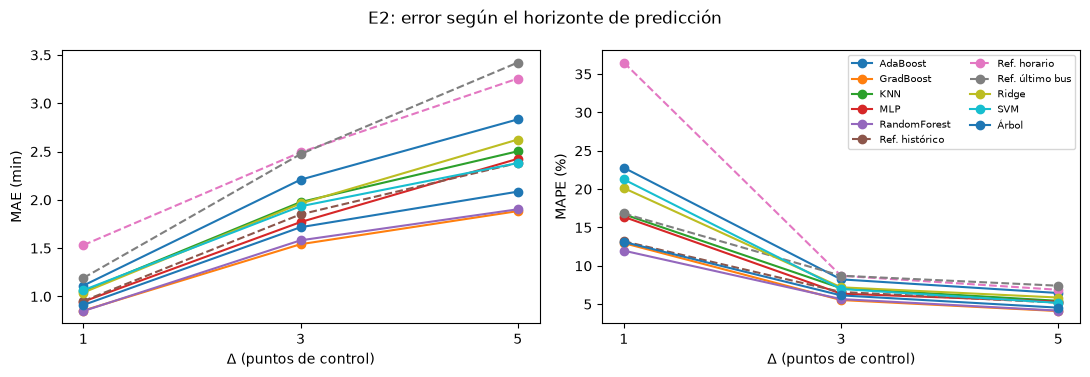

MAE             MAPE_%            
delta               1     3     5      1     3     5
modelo                                              
AdaBoost         1.11  2.21  2.83  22.79  8.23  6.46
GradBoost        0.85  1.54  1.88  12.96  5.54  4.10
KNN              1.05  1.98  2.50  16.72  7.08  5.44
MLP              0.95  1.77  2.42  16.38  6.37  5.33
RandomForest     0.85  1.58  1.90  11.97  5.66  4.16
Ref. histórico   0.95  1.85  2.38  13.20  6.59  5.20
Ref. horario     1.53  2.49  3.26  36.50  8.70  6.88
Ref. último bus  1.19  2.47  3.42  16.82  8.71  7.41
Ridge            1.04  1.96  2.62  20.13  7.20  5.87
SVM              1.06  1.93  2.38  21.26  6.98  5.17
Árbol            0.91  1.72  2.08  13.11  6.15  4.55

In [14]:
E2 = []
for D in DELTAS:
    _, _, tv, te = split(D)
    for k_, v in baselines(tv, te).items():
        E2.append({"delta": D, "modelo": k_, **metrics(te.y, v)})
    for name in REG:
        sc = (E1.set_index("modelo").loc[name].to_dict() if D == DELTA_MAIN
              else evaluate(name, BEST_PRM[name], tv, te, NUM)[2])
        E2.append({"delta": D, "modelo": name, **sc})
E2 = pd.DataFrame(E2)
E2.to_csv(RES / "E2_horizonte.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, g_ in E2.groupby("modelo"):
    style = "o--" if name.startswith("Ref.") else "o-"
    axes[0].plot(g_.delta, g_.MAE, style, label=name)
    axes[1].plot(g_.delta, g_["MAPE_%"], style, label=name)
axes[0].set(xlabel="Δ (puntos de control)", ylabel="MAE (min)", xticks=DELTAS)
axes[1].set(xlabel="Δ (puntos de control)", ylabel="MAPE (%)", xticks=DELTAS)
axes[1].legend(fontsize=7, ncol=2)
fig.suptitle("E2: error según el horizonte de predicción")
fig.tight_layout(); fig.savefig(FIG / "exp2_horizonte.png", dpi=200); plt.show()
E2.pivot_table(index="modelo", columns="delta", values=["MAE", "MAPE_%"]).round(2)

## E3. Ablación de grupos de variables (Gradient Boosting, Δ = 1)

In [15]:
ABL = {"todas": NUM,
       "sin buses recientes": [c for c in NUM if c not in G_REC],
       "sin GPS": [c for c in NUM if c not in G_GPS],
       "sin DBSCAN": [c for c in NUM if c not in G_DB],
       "sin clima": [c for c in NUM if c not in G_CLIMA],
       "sin altitud": [c for c in NUM if c not in G_ALT],
       "sin estado del bus i": [c for c in NUM if c not in G_I],
       "solo contexto": G_CTX}
E3 = pd.DataFrame([{"variables": lab, "n_variables": len(cols),
                    **evaluate("GradBoost", BEST_PRM["GradBoost"], d_trva, d_te, cols)[2]}
                   for lab, cols in ABL.items()])
E3.to_csv(RES / "E3_ablacion.csv", index=False)
E3.round(3)

,variables,n_variables,MAE,RMSE,MAPE_%,R2,t_fit_s,t_pred_s
0,todas,27,0.854,1.257,12.959,0.971,5.473,0.177
1,sin buses recientes,24,0.874,1.305,13.313,0.969,5.220,0.169
2,sin GPS,23,0.857,1.260,13.090,0.971,4.967,0.159
3,sin DBSCAN,24,0.853,1.256,12.994,0.971,6.613,0.216
4,sin clima,21,0.839,1.238,12.631,0.972,7.151,0.237
5,sin altitud,25,0.856,1.260,13.071,0.971,6.614,0.204
6,sin estado del bus i,22,0.906,1.342,13.248,0.967,4.091,0.148
7,solo contexto,4,0.909,1.376,13.102,0.965,3.403,0.125


## E4. Reducción de dimensionalidad con PCA (KNN y SVM, Δ = 1)
PCA conserva el 95 % de la varianza después de estandarizar y aplicar one-hot.

In [16]:
E4 = []
for name in ("KNN", "SVM"):
    for pca in (False, True):
        pipe, _, sc = evaluate(name, BEST_PRM[name], d_trva, d_te, NUM, pca=pca)
        ncomp = pipe.named_steps["pca"].n_components_ if pca else len(pipe.named_steps["prep"].get_feature_names_out())
        E4.append({"modelo": name, "PCA": pca, "dimensiones": ncomp, **sc})
E4 = pd.DataFrame(E4)
E4.to_csv(RES / "E4_pca.csv", index=False)
E4.round(3)

,modelo,PCA,dimensiones,MAE,RMSE,MAPE_%,R2,t_fit_s,t_pred_s
0,KNN,False,72,1.053,1.575,16.717,0.955,0.231,1.413
1,KNN,True,22,1.063,1.594,16.722,0.953,0.228,1.066
2,SVM,False,72,1.065,1.576,21.262,0.954,6.883,11.123
3,SVM,True,22,1.076,1.599,20.478,0.953,6.068,8.668


## E5. Sensibilidad a hiperparámetros y costo computacional
Cada combinación evaluada en validación está en `resultados/E5_busqueda_hiperparametros.csv`.
Se resume cuánto cambia el MAE de validación según los hiperparámetros y los tiempos del modelo final.

In [17]:
S = pd.concat(SEARCH)
E5 = pd.concat([S.groupby("modelo").MAE.agg(["min", "max", "std"]).add_prefix("MAE_val_"),
                E1.set_index("modelo")[["t_fit_s", "t_pred_s"]]], axis=1).dropna(subset=["MAE_val_min"])
E5.to_csv(RES / "E5_resumen.csv")
E5.round(3)

,MAE_val_min,MAE_val_max,MAE_val_std,t_fit_s,t_pred_s
modelo,,,,,
AdaBoost,1.157,2.200,0.462,26.081,0.272
GradBoost,0.912,0.930,0.009,3.964,0.138
KNN,1.162,1.252,0.037,0.210,1.563
MLP,1.005,1.044,0.014,11.043,0.031
RandomForest,0.913,0.941,0.012,16.564,0.170
Ridge,1.125,1.126,0.000,0.333,0.029
SVM,1.158,3.264,0.779,7.945,10.385
Árbol,1.008,1.129,0.056,0.989,0.025


## E6. Análisis de errores y prueba estadística
Error absoluto del mejor modelo frente a la mejor referencia, por tramo y por hora. La prueba de
Wilcoxon (unilateral) compara el MAE por bloques día × tramo del conjunto de prueba.

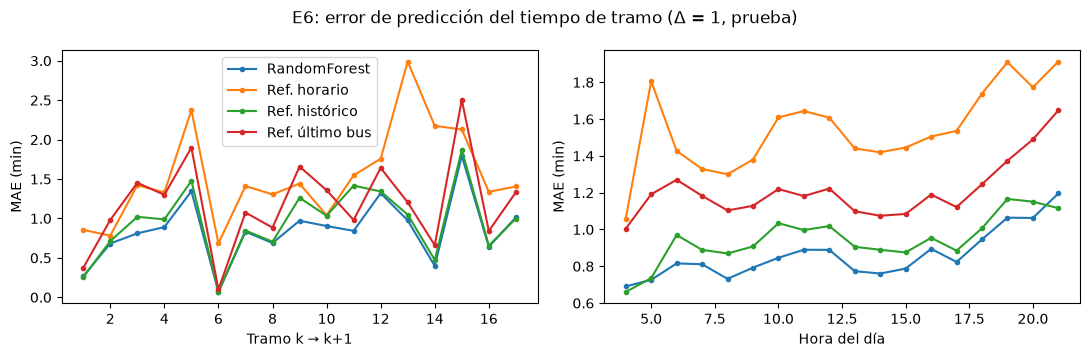

,comparación,bloques,MAE_modelo,MAE_ref,mejora_%,p_valor
0,RandomForest vs. Ref. horario,102,0.8562,1.5431,44.5147,0.0
1,RandomForest vs. Ref. histórico,102,0.8562,0.9621,11.0098,0.0
2,RandomForest vs. Ref. último bus,102,0.8562,1.1980,28.5308,0.0


In [18]:
err = d_te[["date", "k", "hour"]].copy()
err["hora"] = err.hour.astype(int)
for lab in (best, "Ref. horario", "Ref. histórico", "Ref. último bus"):
    err[lab] = np.abs(d_te.y.to_numpy() - PRED[lab])
cols = [best, "Ref. horario", "Ref. histórico", "Ref. último bus"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, lab in ((axes[0], "k", "Tramo k → k+1"), (axes[1], "hora", "Hora del día")):
    g_ = err.groupby(col)
    g_[cols].mean()[g_.size() >= 30].plot(ax=ax, marker="o", ms=3)   # horas con pocos datos son ruido
    ax.set(xlabel=lab, ylabel="MAE (min)")
axes[1].get_legend().remove()
fig.suptitle(f"E6: error de predicción del tiempo de tramo (Δ = {DELTA_MAIN}, prueba)")
fig.tight_layout(); fig.savefig(FIG / "exp6_errores.png", dpi=200); plt.show()

blk = err.groupby(["date", "k"])[cols].mean()
W = []
for ref in cols[1:]:
    _, pval = wilcoxon(blk[best], blk[ref], alternative="less")
    W.append({"comparación": f"{best} vs. {ref}", "bloques": len(blk), "MAE_modelo": blk[best].mean(),
              "MAE_ref": blk[ref].mean(), "mejora_%": 100 * (1 - blk[best].mean() / blk[ref].mean()), "p_valor": pval})
W = pd.DataFrame(W)
W.to_csv(RES / "E6_wilcoxon.csv", index=False)
W.round(4)

## Resumen para el informe
Hipótesis del Entregable 1: el mejor modelo reduce el MAE en al menos 15 % frente a la mejor referencia.

In [19]:
mae = E1.set_index("modelo").MAE
mejora = 100 * (1 - mae[best] / mae[best_ref])
print(f"Δ={DELTA_MAIN} | {best}: MAE {mae[best]:.2f} min | mejor referencia ({best_ref}): {mae[best_ref]:.2f} min "
      f"| mejora {mejora:.1f} % -> hipótesis {'confirmada' if mejora >= 15 else 'no confirmada'}")
print("archivos:", sorted(str(x) for x in list(RES.iterdir()) + list(MOD.iterdir())))

Δ=1 | RandomForest: MAE 0.85 min | mejor referencia (Ref. histórico): 0.95 min | mejora 10.9 % -> hipótesis no confirmada
archivos: ['modelos\\eta_GradBoost_delta1.joblib', 'modelos\\eta_RandomForest_delta1.joblib', 'resultados\\E1_eta_delta1.csv', 'resultados\\E2_horizonte.csv', 'resultados\\E3_ablacion.csv', 'resultados\\E4_pca.csv', 'resultados\\E5_busqueda_hiperparametros.csv', 'resultados\\E5_resumen.csv', 'resultados\\E6_wilcoxon.csv', 'resultados\\dataset_modelo.pkl', 'resultados\\paraderos_dbscan.csv', 'resultados\\puntos_control.csv']
